In [ ]:

import kagglehub
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
import random

from pathlib import Path
from sklearn.cluster import KMeans

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

dataset_download_path = kagglehub.dataset_download(
    "abdallahalidev/plantvillage-dataset"
)

print("Kaggle download path:", dataset_download_path)

download_root = Path(dataset_download_path)

# Find the directory that contains the actual class folders.
possible_paths = [
    download_root / "plantvillage dataset" / "color",
    download_root / "PlantVillage" / "color",
    download_root / "color",
    download_root
]

RAW_DATASET_PATH = None

for candidate in possible_paths:
    if candidate.is_dir():
        if candidate.name.lower() == "color":
            RAW_DATASET_PATH = candidate
            break

if RAW_DATASET_PATH is None:
    for candidate in download_root.rglob("color"):
        if candidate.is_dir():
            RAW_DATASET_PATH = candidate
            break

if RAW_DATASET_PATH is None:
    raise FileNotFoundError(
        f"Could not find the color directory under {download_root}"
    )

print("Using Kaggle image directory:", RAW_DATASET_PATH)
print("Example folders:", [
    p.name for p in list(RAW_DATASET_PATH.iterdir())[:10]
])


Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Kaggle download path: /kaggle/input/plantvillage-dataset
Using Kaggle image directory: /kaggle/input/plantvillage-dataset/plantvillage dataset/color
Example folders: ['Tomato___Late_blight', 'Tomato___healthy', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Potato___healthy', 'Corn_(maize)___Northern_Leaf_Blight', 'Tomato___Early_blight', 'Tomato___Septoria_leaf_spot']


In [ ]:

SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

class_names = sorted(
    folder.name
    for folder in RAW_DATASET_PATH.iterdir()
    if folder.is_dir()
    and any(
        f.is_file() and f.suffix.lower() in SUPPORTED_EXTENSIONS
        for f in folder.iterdir()
    )
)

if not class_names:
    raise ValueError(
        "No image class folders found. Check the printed directory."
    )

image_records = []

for label, class_name in enumerate(class_names):
    class_folder = RAW_DATASET_PATH / class_name

    for image_file in sorted(class_folder.iterdir()):
        if image_file.is_file() and image_file.suffix.lower() in SUPPORTED_EXTENSIONS:
            image_records.append({
                "path": str(image_file),
                "label": label,
                "class_name": class_name
            })

image_df = pd.DataFrame(image_records)

if image_df.empty:
    raise ValueError("No images found in the Kaggle dataset.")

# Keep only tomato classes.
tomato_df = image_df[
    image_df["class_name"].str.lower().str.startswith("tomato")
].copy()

print("Total PlantVillage images:", len(image_df))
print("Total PlantVillage classes:", len(class_names))
print("Tomato images:", len(tomato_df))
print("Tomato classes:", tomato_df["class_name"].nunique())

print("\nTomato class counts:")
print(tomato_df["class_name"].value_counts().sort_index())

if tomato_df.empty:
    print("\nAvailable class names:")
    print("\n".join(class_names))
    raise ValueError("No tomato classes found.")


Total PlantVillage images: 54305
Total PlantVillage classes: 38
Tomato images: 18160
Tomato classes: 10

Tomato class counts:
class_name
Tomato___Bacterial_spot                          2127
Tomato___Early_blight                            1000
Tomato___Late_blight                             1909
Tomato___Leaf_Mold                                952
Tomato___Septoria_leaf_spot                      1771
Tomato___Spider_mites Two-spotted_spider_mite    1676
Tomato___Target_Spot                             1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus           5357
Tomato___Tomato_mosaic_virus                      373
Tomato___healthy                                 1591
Name: count, dtype: int64


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

from pathlib import Path
from sklearn.cluster import KMeans

# ============================================================
# 1. SETTINGS
# ============================================================
SEED = 42
IMG_SIZE = 256
N_CLUSTERS = 3
SAMPLES_PER_CLASS = 5

random.seed(SEED)
np.random.seed(SEED)

# Reuse the tomato_df already created from Kaggle PlantVillage.
assert "tomato_df" in globals(), (
    "Run your Kaggle dataset and tomato_df creation cells first."
)

tomato_classes = sorted(tomato_df["class_name"].unique())

print("Dataset: Kaggle PlantVillage / color")
print("Tomato images:", len(tomato_df))
print("Tomato classes:", len(tomato_classes))


# ============================================================
# 2. BACKGROUND REMOVAL
# Paper-inspired sequence:
# green channel -> Canny -> dilation -> fill contours
# -> intensity thresholding
# ============================================================
def remove_background(rgb):
    green = rgb[:, :, 1]

    # Normalize the green channel.
    green = cv2.normalize(
        green, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

    # Canny edge detection.
    edges = cv2.Canny(green, 30, 80)

    # Dilate edges to connect nearby boundaries.
    kernel = np.ones((5, 5), np.uint8)
    dilated = cv2.dilate(edges, kernel, iterations=2)

    # Fill closed external contours.
    contours, _ = cv2.findContours(
        dilated,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    mask = np.zeros(green.shape, dtype=np.uint8)

    if contours:
        # Fill all reasonably sized external contours.
        min_area = rgb.shape[0] * rgb.shape[1] * 0.005

        for contour in contours:
            if cv2.contourArea(contour) >= min_area:
                cv2.drawContours(
                    mask, [contour], -1, 255, thickness=cv2.FILLED
                )

    # Approximate shadow/intensity thresholding.
    # Threshold value is an implementation choice.
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    mask[gray < 25] = 0

    # Morphological cleanup.
    mask = cv2.morphologyEx(
        mask, cv2.MORPH_CLOSE,
        np.ones((5, 5), np.uint8), iterations=1
    )

    # Preserve original leaf colors; set background to black.
    background_removed = np.zeros_like(rgb)
    background_removed[mask > 0] = rgb[mask > 0]

    return background_removed, mask, green, dilated


# ============================================================
# 3. K-MEANS CLUSTERING
# Cluster pixels inside the foreground mask.
# ============================================================
def kmeans_segment(rgb, mask=None, k=3):
    h, w = rgb.shape[:2]

    if mask is None:
        valid = np.ones((h, w), dtype=bool)
    else:
        valid = mask > 0

    pixels = rgb[valid].astype(np.float32)

    if len(pixels) < k:
        return np.zeros_like(rgb)

    model = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    cluster_labels = model.fit_predict(pixels)

    # Reconstruct the clustered image.
    centers = np.clip(
        model.cluster_centers_, 0, 255
    ).astype(np.uint8)

    segmented = np.zeros_like(rgb)
    segmented[valid] = centers[cluster_labels]

    return segmented


# ============================================================
# 4. DISEASE-AREA EXTRACTION
# Paper's stated color rule:
# retain pixels where R < G AND R < B.
# ============================================================
def extract_disease_area(rgb, leaf_mask):
    r = rgb[:, :, 0].astype(np.int16)
    g = rgb[:, :, 1].astype(np.int16)
    b = rgb[:, :, 2].astype(np.int16)

    disease_mask = (r < g) & (r < b)

    # Exclude pixels outside the estimated leaf foreground.
    disease_mask &= leaf_mask > 0

    disease_mask = disease_mask.astype(np.uint8) * 255

    disease_area = np.zeros_like(rgb)
    disease_area[disease_mask > 0] = rgb[disease_mask > 0]

    return disease_area, disease_mask


# ============================================================
# 5. INSPECT FIVE IMAGES PER TOMATO CLASS
# ============================================================
for class_name in tomato_classes:

    class_records = tomato_df[
        tomato_df["class_name"] == class_name
    ]

    selected = class_records.sample(
        n=min(SAMPLES_PER_CLASS, len(class_records)),
        random_state=SEED
    )

    print(
        f"\nClass: {class_name} | "
        f"Total images: {len(class_records)} | "
        f"Samples: {len(selected)}"
    )

    fig, axes = plt.subplots(
        len(selected), 5,
        figsize=(19, 4 * len(selected)),
        squeeze=False
    )

    for row, (_, record) in enumerate(selected.iterrows()):

        image_path = Path(record["path"])
        bgr = cv2.imread(str(image_path))

        if bgr is None:
            print("Could not read:", image_path)
            continue

        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        rgb = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE))

        # Step A: remove background.
        no_background, leaf_mask, green, edges = remove_background(rgb)

        # Step B: K-means on the original image.
        km_original = kmeans_segment(
            rgb, k=N_CLUSTERS
        )

        # Step C: K-means on the background-removed image.
        km_leaf = kmeans_segment(
            no_background,
            mask=leaf_mask,
            k=N_CLUSTERS
        )

        # Step D: apply the paper's disease-area color rule.
        disease_area, disease_mask = extract_disease_area(
            no_background, leaf_mask
        )

        outputs = [
            rgb,
            no_background,
            km_original,
            km_leaf,
            disease_area
        ]

        titles = [
            "1. Original",
            "2. Background removed",
            "3. K-means: original",
            "4. K-means: leaf region",
            "5. Disease-area candidate"
        ]

        for col, (output, title) in enumerate(
            zip(outputs, titles)
        ):
            axes[row, col].imshow(output)
            axes[row, col].set_title(title, fontsize=9)
            axes[row, col].axis("off")

        axes[row, 0].set_ylabel(
            image_path.name[:22],
            fontsize=8
        )

    fig.suptitle(
        f"Tomato disease segmentation — {class_name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


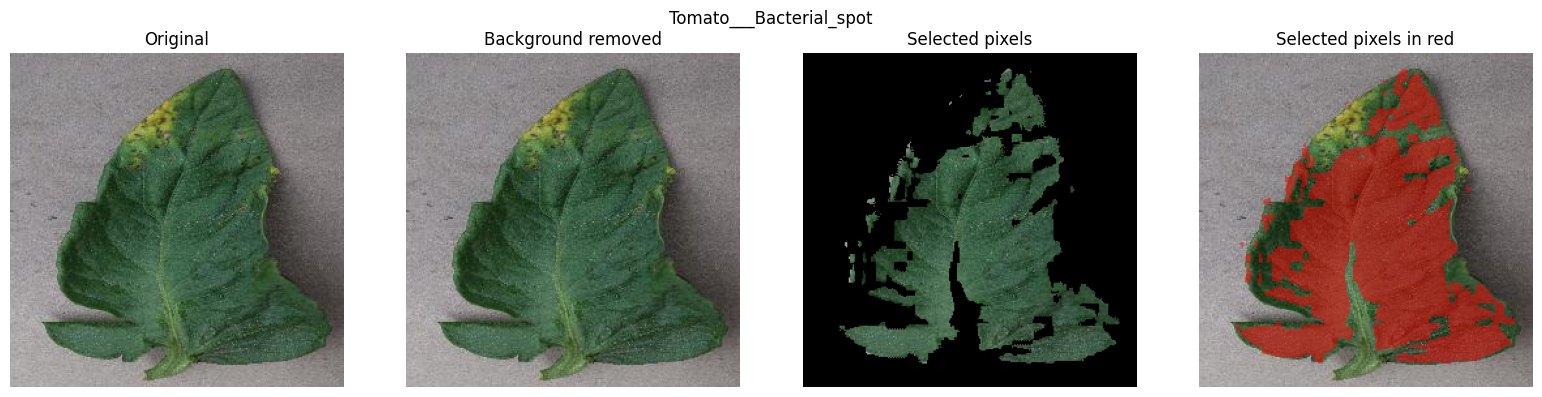

Image: /kaggle/input/plantvillage-dataset/plantvillage dataset/color/Tomato___Bacterial_spot/23642d88-83e5-491d-b9f2-7ddac809975b___GCREC_Bact.Sp 6186.JPG
Selected foreground pixels: 21,528
Selected pixel percentage: 32.85%


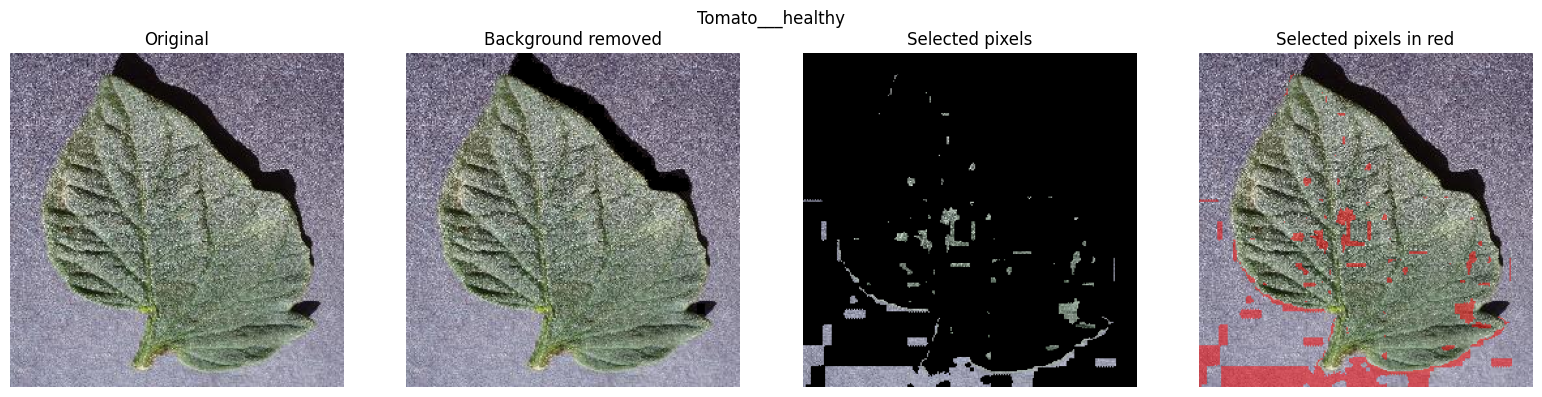

Image: /kaggle/input/plantvillage-dataset/plantvillage dataset/color/Tomato___healthy/adb15e56-fb9c-4b1f-aae1-4ec8bedecd1b___RS_HL 9712.JPG
Selected foreground pixels: 4,742
Selected pixel percentage: 7.24%


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def inspect_tomato_class(class_name, seed=42):
    records = tomato_df[tomato_df["class_name"] == class_name]

    if records.empty:
        print(f"Class not found: {class_name}")
        return

    record = records.sample(n=1, random_state=seed).iloc[0]

    bgr = cv2.imread(record["path"])
    if bgr is None:
        print("Could not read image:", record["path"])
        return

    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(rgb, (256, 256))

    # Use the existing paper-inspired functions.
    no_bg, leaf_mask, green, edges = remove_background(rgb)
    disease_area, disease_mask = extract_disease_area(
        no_bg, leaf_mask
    )

    # Overlay selected pixels on the original for easier inspection.
    overlay = rgb.copy()
    selected = disease_mask > 0
    overlay[selected] = (
        0.5 * overlay[selected] + 0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    outputs = [
        (rgb, "Original"),
        (no_bg, "Background removed"),
        (disease_area, "Selected pixels"),
        (overlay, "Selected pixels in red")
    ]

    for ax, (image, title) in zip(axes, outputs):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

    plt.suptitle(class_name)
    plt.tight_layout()
    plt.show()

    print("Image:", record["path"])
    print(f"Selected foreground pixels: {selected.sum():,}")
    print(f"Selected pixel percentage: {100 * selected.mean():.2f}%")


inspect_tomato_class("Tomato___Bacterial_spot")
inspect_tomato_class("Tomato___healthy")


In [ ]:
pip install opencv-python numpy pandas matplotlib scikit-learn scikit-image tqdm


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# ============================================================
# SETTINGS
# ============================================================
IMG_SIZE = 256
K_CLUSTERS = 3
SAMPLES_PER_CLASS = 5
SEED = 42

assert "tomato_df" in globals(), (
    "Run your Kaggle dataset-loading cell that creates tomato_df first."
)

# ============================================================
# STEP 1: BACKGROUND REMOVAL
# Paper: green channel, Canny, dilation, fill, gray threshold
# Input and output images use RGB ordering in this function.
# ============================================================
def remove_leaf_background(rgb):
    rgb = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE))

    # Extract green channel.
    green = rgb[:, :, 1]
    blurred = cv2.GaussianBlur(green, (5, 5), 0)

    # Edge detection.
    edges = cv2.Canny(blurred, 30, 100)

    # Connect edges by morphological dilation.
    kernel = np.ones((5, 5), np.uint8)
    dilated = cv2.dilate(edges, kernel, iterations=2)
    closed = cv2.morphologyEx(
        dilated, cv2.MORPH_CLOSE, kernel, iterations=2
    )

    # Fill external contours.
    contours, _ = cv2.findContours(
        closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    mask = np.zeros(green.shape, dtype=np.uint8)

    if contours:
        # Keep the largest external contour as the leaf candidate.
        largest = max(contours, key=cv2.contourArea)
        cv2.drawContours(mask, [largest], -1, 255, cv2.FILLED)

    # Fallback if the edge mask is too small.
    if np.count_nonzero(mask) < 0.05 * mask.size:
        hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
        green_mask = cv2.inRange(
            hsv,
            np.array([20, 20, 15], dtype=np.uint8),
            np.array([100, 255, 255], dtype=np.uint8)
        )
        contours, _ = cv2.findContours(
            green_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        mask[:] = 0
        if contours:
            largest = max(contours, key=cv2.contourArea)
            cv2.drawContours(mask, [largest], -1, 255, cv2.FILLED)

    # Remove very small connected components.
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )
    if count > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask = (labels == largest_label).astype(np.uint8) * 255

    # Gray-level thresholding to suppress very dark pixels/shadows.
    # Threshold 20 is an implementation choice, not a paper-specified value.
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    mask[gray < 20] = 0

    leaf = np.zeros_like(rgb)
    leaf[mask > 0] = rgb[mask > 0]

    return leaf, mask


# ============================================================
# STEP 2: K-MEANS ON LEAF PIXELS ONLY
# ============================================================
def cluster_leaf_pixels(rgb, leaf_mask, k=K_CLUSTERS):
    valid = leaf_mask > 0
    pixels = rgb[valid].astype(np.float32)

    clustered = np.zeros_like(rgb)

    if len(pixels) < k:
        return clustered, np.zeros(leaf_mask.shape, dtype=np.int32)

    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        100, 0.2
    )

    _, labels, centers = cv2.kmeans(
        pixels, k, None, criteria, 10, cv2.KMEANS_PP_CENTERS
    )

    centers = np.clip(centers, 0, 255).astype(np.uint8)

    # Reconstruct the clustered leaf.
    clustered[valid] = centers[labels.flatten()]

    label_map = np.full(leaf_mask.shape, -1, dtype=np.int32)
    label_map[valid] = labels.flatten()

    return clustered, label_map


# ============================================================
# STEP 3: PAPER'S DISEASE-AREA RULE
# Mask out pixels where R < G AND R < B.
# Retain the remaining leaf pixels as disease-area candidates.
# ============================================================
def extract_disease_area(rgb, leaf_mask, clustered):
    # The paper's condition is defined on RGB channels.
    R = clustered[:, :, 0].astype(np.int16)
    G = clustered[:, :, 1].astype(np.int16)
    B = clustered[:, :, 2].astype(np.int16)

    # These pixels are removed, not retained.
    healthy_rule = (R < G) & (R < B)

    # Keep pixels within the leaf that do NOT satisfy the rule.
    candidate_mask = (
        (leaf_mask > 0) & (~healthy_rule)
    ).astype(np.uint8) * 255

    # Preserve the original leaf colors in the final output.
    disease_candidate = np.zeros_like(rgb)
    selected = candidate_mask > 0
    disease_candidate[selected] = rgb[selected]

    return disease_candidate, candidate_mask


# ============================================================
# STEP 4: DISPLAY FIVE IMAGES PER TOMATO CLASS
# ============================================================
tomato_classes = sorted(tomato_df["class_name"].unique())

for class_name in tomato_classes:
    class_df = tomato_df[tomato_df["class_name"] == class_name]

    samples = class_df.sample(
        n=min(SAMPLES_PER_CLASS, len(class_df)),
        random_state=SEED
    )

    print(f"\nClass: {class_name}")
    print("Total images:", len(class_df))

    fig, axes = plt.subplots(
        len(samples), 5,
        figsize=(18, 3.5 * len(samples)),
        squeeze=False
    )

    for row, (_, record) in enumerate(samples.iterrows()):
        bgr = cv2.imread(str(record["path"]))

        if bgr is None:
            for ax in axes[row]:
                ax.axis("off")
            continue

        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        rgb = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE))

        # Background removal.
        leaf, leaf_mask = remove_leaf_background(rgb)

        # K-means clustering.
        clustered, cluster_labels = cluster_leaf_pixels(
            leaf, leaf_mask
        )

        # Disease-area candidate extraction.
        candidate, candidate_mask = extract_disease_area(
            rgb, leaf_mask, clustered
        )

        # Red overlay highlights retained candidate pixels.
        overlay = rgb.copy()
        selected = candidate_mask > 0
        overlay[selected] = (
            0.5 * overlay[selected]
            + 0.5 * np.array([255, 0, 0])
        ).astype(np.uint8)

        outputs = [
            rgb,
            leaf,
            clustered,
            candidate,
            overlay
        ]

        titles = [
            "1. Original",
            "2. Background removed",
            "3. K-means leaf",
            "4. Disease-area candidate",
            "5. Candidate overlay"
        ]

        for col, (image, title) in enumerate(zip(outputs, titles)):
            axes[row, col].imshow(image)
            axes[row, col].set_title(title, fontsize=9)
            axes[row, col].axis("off")

        axes[row, 0].set_ylabel(
            Path(record["path"]).name[:18], fontsize=8
        )

        print(
            f"  {Path(record['path']).name}: "
            f"{100 * np.mean(selected):.1f}% of image retained"
        )

    fig.suptitle(
        f"Paper-inspired disease-area extraction: {class_name}",
        fontsize=13
    )
    plt.tight_layout()
    plt.show()


In [ ]:
# ============================================================
# TOMATO-ONLY K-MEANS SEGMENTATION VISUALIZATION
# Based on the uploaded ML_segmentation.ipynb
#
# Displays:
# 1. Original image
# 2. K-means clusters
# 3. Background-removed leaf
# 4. Disease-area candidate
#
# Only a few images per tomato class are processed.
# No GrabCut. No output files are saved.
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from pathlib import Path


# ============================================================
# 1. FIND THE PLANTVILLAGE COLOR DIRECTORY
# ============================================================

try:
    DATASET_ROOT = Path(RAW_DATASET_PATH)
except NameError:
    DATASET_ROOT = Path("/kaggle/input/plantvillage-dataset")

if DATASET_ROOT.name.lower() == "color":
    COLOR_DIR = DATASET_ROOT

elif (DATASET_ROOT / "color").is_dir():
    COLOR_DIR = DATASET_ROOT / "color"

else:
    color_dirs = [
        p for p in DATASET_ROOT.rglob("color")
        if p.is_dir()
        and any(
            d.is_dir() and d.name.startswith("Tomato")
            for d in p.iterdir()
        )
    ]

    if not color_dirs:
        raise FileNotFoundError(
            f"Could not find the PlantVillage color directory "
            f"under {DATASET_ROOT}"
        )

    COLOR_DIR = color_dirs[0]

print("Dataset directory:", COLOR_DIR)


# ============================================================
# 2. K-MEANS SETTINGS FROM YOUR NOTEBOOK
# ============================================================

KM_K = 3
KM_BORDER = 0.05
KM_BG_BORDER_SHARE = 0.40
KM_BLUR = 5
KM_MORPH = 5
KM_SEED = 0

DA_K = 2
DA_MIN_SEP = 10.0
DA_MAX_GREEN_A = -4.0

SEG_MIN_COVER = 0.02
SEG_MAX_COVER = 0.98


# ============================================================
# 3. K-MEANS HELPER
# ============================================================

def _kmeans(X, k):
    cv2.setRNGSeed(KM_SEED)

    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        15,
        0.5
    )

    _, labels, centers = cv2.kmeans(
        np.ascontiguousarray(X, dtype=np.float32),
        k,
        None,
        criteria,
        1,
        cv2.KMEANS_PP_CENTERS
    )

    return labels.ravel(), centers


# ============================================================
# 4. KEEP THE LARGEST CONNECTED REGION
# ============================================================

def _largest_blob(mask):
    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8),
        connectivity=8
    )

    if n <= 1:
        return mask

    largest = 1 + int(
        np.argmax(stats[1:, cv2.CC_STAT_AREA])
    )

    return labels == largest


# ============================================================
# 5. FILL HOLES INSIDE THE LEAF
# ============================================================

def _fill_holes(mask):
    H, W = mask.shape

    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        (~mask).astype(np.uint8),
        connectivity=8
    )

    output = mask.copy()

    for i in range(1, n):
        x, y, w, h = stats[i, :4]

        # Fill only holes that do not touch the image border.
        if not (
            x == 0 or y == 0
            or x + w == W or y + h == H
        ):
            output[labels == i] = True

    return output


# ============================================================
# 6. MAIN K-MEANS SEGMENTATION
# Same algorithm as your uploaded notebook
# ============================================================

def kmeans_segment(img_rgb):
    """
    Input:
        RGB uint8 image of shape (H, W, 3)

    Output:
        leaf_mask, disease_mask, cluster_img

    Masks are boolean arrays.
    cluster_img is an RGB visualization of K-means clusters.
    """

    img = np.ascontiguousarray(img_rgb, dtype=np.uint8)
    H, W = img.shape[:2]

    # --------------------------------------------------------
    # STEP 1: K-means background removal in Lab color space
    # --------------------------------------------------------

    lab = cv2.cvtColor(
        img, cv2.COLOR_RGB2LAB
    ).astype(np.float32)

    lab = cv2.GaussianBlur(
        lab, (KM_BLUR, KM_BLUR), 0
    )

    # Cluster a* and b* channels.
    ab = lab[..., 1:].reshape(-1, 2).copy()

    labels, _ = _kmeans(ab, KM_K)
    labels = labels.reshape(H, W)

    # Border ring used to identify background clusters.
    border_width = max(
        2, int(KM_BORDER * min(H, W))
    )

    ring = np.zeros((H, W), dtype=bool)

    ring[:border_width, :] = True
    ring[-border_width:, :] = True
    ring[:, :border_width] = True
    ring[:, -border_width:] = True

    # Proportion of border pixels belonging to each cluster.
    border_share = np.array([
        (labels[ring] == c).mean()
        for c in range(KM_K)
    ])

    background_clusters = (
        border_share >= KM_BG_BORDER_SHARE
    )

    # Fallback: choose the cluster most represented on the border.
    if not background_clusters.any():
        background_clusters[
            int(np.argmax(border_share))
        ] = True

    # If every cluster appears to be background, segmentation fails.
    if background_clusters.all():
        return None, None, None

    # Build leaf mask.
    leaf_mask = ~background_clusters[labels]

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (KM_MORPH, KM_MORPH)
    )

    leaf_mask = cv2.morphologyEx(
        leaf_mask.astype(np.uint8),
        cv2.MORPH_OPEN,
        kernel
    ).astype(bool)

    leaf_mask = _fill_holes(
        _largest_blob(leaf_mask)
    )

    # K-means cluster visualization.
    cluster_img = np.zeros_like(img)

    for c in range(KM_K):
        selected = labels == c

        if selected.any():
            mean_color = img[selected].mean(axis=0)

            cluster_img[selected] = np.clip(
                mean_color, 0, 255
            ).astype(np.uint8)

    # --------------------------------------------------------
    # STEP 2: K-means disease-area candidate within the leaf
    # --------------------------------------------------------

    disease_mask = np.zeros(
        (H, W), dtype=bool
    )

    if leaf_mask.sum() > 200:

        leaf_ab = lab[..., 1:][leaf_mask].astype(
            np.float32
        )

        disease_labels, centers = _kmeans(
            leaf_ab, DA_K
        )

        # The cluster with higher Lab a* is treated as
        # the less-green / potential disease cluster.
        disease_cluster = int(
            np.argmax(centers[:, 0])
        )

        separation = float(
            np.linalg.norm(centers[0] - centers[1])
        )

        a_difference = float(
            centers[disease_cluster, 0] - 128.0
        )

        if (
            separation >= DA_MIN_SEP
            and a_difference > DA_MAX_GREEN_A
        ):
            disease_mask[leaf_mask] = (
                disease_labels == disease_cluster
            )

    return leaf_mask, disease_mask, cluster_img


# ============================================================
# 7. LOAD AND RESIZE IMAGES
# ============================================================

IMAGE_SIZE = 256

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}


def load_image(path):
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(f"Could not read image: {path}")

    image = cv2.cvtColor(
        image, cv2.COLOR_BGR2RGB
    )

    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    return image


# ============================================================
# 8. FIND TOMATO CLASSES AND SAMPLE IMAGES
# ============================================================

SAMPLES_PER_CLASS = 3
RANDOM_SEED = 42

rng = random.Random(RANDOM_SEED)

tomato_classes = sorted([
    folder for folder in COLOR_DIR.iterdir()
    if folder.is_dir()
    and folder.name.startswith("Tomato")
])

if not tomato_classes:
    raise RuntimeError(
        f"No tomato class folders found in {COLOR_DIR}"
    )

print("\nTomato classes found:", len(tomato_classes))

tomato_samples = []

for class_dir in tomato_classes:

    image_paths = [
        p for p in class_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    rng.shuffle(image_paths)

    selected_images = image_paths[:SAMPLES_PER_CLASS]

    for path in selected_images:
        tomato_samples.append(
            (class_dir.name, path)
        )

    print(
        f"{class_dir.name}: "
        f"{len(selected_images)} images selected"
    )

print("\nTotal images selected:", len(tomato_samples))


# ============================================================
# 9. VISUALIZE THE FOUR RESULTS
# ============================================================

def visualize_tomato_samples(samples):

    if not samples:
        print("No images to display.")
        return

    fig, axes = plt.subplots(
        len(samples),
        4,
        figsize=(16, 3.8 * len(samples)),
        squeeze=False
    )

    leaf_coverages = []
    disease_coverages = []
    errors = []

    for row_index, (class_name, image_path) in enumerate(samples):

        row = axes[row_index]

        try:
            image = load_image(image_path)

            # This function returns exactly three values.
            leaf_mask, disease_mask, cluster_img = (
                kmeans_segment(image)
            )

            if leaf_mask is None:
                row[0].imshow(image)
                row[0].set_title("Original")
                row[0].axis("off")

                for col in range(1, 4):
                    row[col].text(
                        0.5, 0.5,
                        "Leaf segmentation\nnot detected",
                        ha="center",
                        va="center"
                    )
                    row[col].axis("off")

                errors.append(
                    (str(image_path), "No sensible leaf mask")
                )
                continue

            # Keep original colors; make background black.
            background_removed = np.zeros_like(image)
            background_removed[leaf_mask] = image[leaf_mask]

            # Keep only candidate disease-area pixels.
            disease_area = np.zeros_like(image)
            disease_area[disease_mask] = image[disease_mask]

            leaf_coverage = 100.0 * leaf_mask.mean()

            if leaf_mask.sum() > 0:
                disease_coverage = (
                    100.0 * disease_mask.sum()
                    / leaf_mask.sum()
                )
            else:
                disease_coverage = 0.0

            leaf_coverages.append(leaf_coverage)
            disease_coverages.append(disease_coverage)

            panels = [
                (image, "Original"),
                (cluster_img, "K-means clusters"),
                (
                    background_removed,
                    f"Background removed\n"
                    f"Leaf coverage: {leaf_coverage:.1f}%"
                ),
                (
                    disease_area,
                    f"Disease-area candidate\n"
                    f"{disease_coverage:.1f}% of leaf"
                )
            ]

            for col, (panel, title) in enumerate(panels):
                row[col].imshow(panel)
                row[col].set_title(title, fontsize=10)
                row[col].axis("off")

            row[0].set_ylabel(
                class_name.replace("Tomato___", ""),
                fontsize=9
            )

        except Exception as e:
            errors.append((str(image_path), str(e)))

            for ax in row:
                ax.clear()
                ax.axis("off")

            row[0].text(
                0.5, 0.5,
                f"Error:\n{str(e)[:150]}",
                ha="center",
                va="center",
                wrap=True
            )

    plt.suptitle(
        "Tomato K-means Segmentation",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

    print("\n========== SUMMARY ==========")
    print("Images selected:", len(samples))
    print("Images with errors or failed masks:", len(errors))

    if leaf_coverages:
        print(
            f"Average leaf coverage: "
            f"{np.mean(leaf_coverages):.2f}%"
        )

        print(
            f"Average disease-area candidate: "
            f"{np.mean(disease_coverages):.2f}% of detected leaf"
        )

    if errors:
        print("\nFirst errors:")
        for path, error in errors[:5]:
            print(path, "->", error)


# ============================================================
# 10. RUN VISUAL INSPECTION
# ============================================================

visualize_tomato_samples(tomato_samples)

In [ ]:
!pip install -q --upgrade gdown

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip -q install gdown

import requests
from bs4 import BeautifulSoup

url = "https://drive.google.com/drive/folders/1tW8FrGHjNJtog20hviqP2KOoTlASRGhi"

r = requests.get(url)
print("HTTP status:", r.status_code)

soup = BeautifulSoup(r.text, "html.parser")
print(soup.get_text()[:3000])

HTTP status: 200
tomato_grey_refined_segmented_COMPLETE - Google 雲端硬碟你必須啟用 JavaScript 才能使用 Google 雲端硬碟瞭解詳情跳到主要內容鍵盤快速鍵無障礙工具意見回饋系統已不再支援這個瀏覽器版本，請升級為支援的瀏覽器。瞭解詳情關閉雲端硬碟雲端硬碟登入雲端硬碟雲端硬碟NameDate modifiedFile size查看排序選項排序查看排序選項排序依據NameDate modified排序方向A to ZZ to A資料夾位於上方與檔案混合Tomato___Bacterial_spot10月19日— DownloadTomato___Early_blight10月19日— DownloadTomato___healthy10月19日— DownloadTomato___Late_blight10月19日— DownloadTomato___Leaf_Mold10月19日— DownloadTomato___Septoria_leaf_spot10月19日— DownloadTomato___Spider_mites Two-spotted_spider_mite10月19日— DownloadTomato___Target_Spot10月19日— DownloadTomato___Tomato_mosaic_virus10月19日— DownloadTomato___Tomato_Yellow_Leaf_Curl_Virus10月19日— DownloadGoogle 應用程式主選單


In [ ]:
from google.colab import drive
from pathlib import Path

TARGET = Path(
    "/content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE"
)

if TARGET.exists():
    print("Folder found:", TARGET)
    subfolders = sorted(p.name for p in TARGET.iterdir() if p.is_dir())

    print(f"\nSubfolders ({len(subfolders)}):")
    for name in subfolders:
        print(name)
else:
    print("Folder not found at:", TARGET)
    print("\nMyDrive contents:")
    for p in Path("/content/drive/MyDrive").iterdir():
        print(p.name)

Folder found: /content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE

Subfolders (10):
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
import random

TARGET = Path(
    "/content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE"
)

N_SAMPLES = 3
SEED = 42

# Disease-area parameters from the notebook
DA_K = 2
DA_MIN_SEP = 10.0
DA_MAX_GREEN_A = -4.0

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

assert TARGET.is_dir(), f"Folder not found: {TARGET}"

In [ ]:
def kmeans_disease_only(image_path):
    image = cv2.imread(str(image_path), cv2.IMREAD_UNCHANGED)

    if image is None:
        raise ValueError(f"Could not read: {image_path}")

    # Convert image to RGB and obtain foreground from existing GrabCut output
    if image.ndim == 2:
        rgb = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        alpha = None
    elif image.shape[2] == 4:
        rgb = cv2.cvtColor(image[:, :, :3], cv2.COLOR_BGR2RGB)
        alpha = image[:, :, 3]
    else:
        rgb = cv2.cvtColor(image[:, :, :3], cv2.COLOR_BGR2RGB)
        alpha = None

    # Reuse existing foreground: alpha channel or black-background mask
    if alpha is not None and np.any(alpha == 0):
        leaf_mask = alpha > 0
    else:
        leaf_mask = np.any(rgb > 12, axis=2)

    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    ab_pixels = lab[leaf_mask][:, 1:3].astype(np.float32)

    disease_mask = np.zeros(leaf_mask.shape, dtype=bool)

    if len(ab_pixels) < 50:
        return rgb, leaf_mask, disease_mask, np.zeros_like(rgb)

    model = KMeans(
        n_clusters=DA_K,
        random_state=SEED,
        n_init=10
    )
    labels = model.fit_predict(ab_pixels)
    centers = model.cluster_centers_

    # Same selection logic as the notebook:
    # higher Lab a* cluster is a disease candidate if separation is sufficient
    green_cluster = np.argmin(centers[:, 0])
    candidate_cluster = np.argmax(centers[:, 0])

    separation = (
        centers[candidate_cluster, 0] - centers[green_cluster, 0]
    )
    candidate_a_offset = centers[candidate_cluster, 0] - 128.0

    if (
        candidate_cluster != green_cluster
        and separation >= DA_MIN_SEP
        and candidate_a_offset > DA_MAX_GREEN_A
    ):
        disease_mask[leaf_mask] = labels == candidate_cluster

    disease_only = np.zeros_like(rgb)
    disease_only[disease_mask] = rgb[disease_mask]

    return rgb, leaf_mask, disease_mask, disease_only

In [ ]:
random.seed(SEED)

disease_classes = sorted(
    p for p in TARGET.iterdir()
    if p.is_dir() and p.name != "Tomato___healthy"
)

print("Disease classes:", len(disease_classes))
print("Images processed per class: up to", N_SAMPLES)

for class_dir in disease_classes:
    image_paths = sorted(
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    if not image_paths:
        print(f"No images found: {class_dir.name}")
        continue

    samples = random.sample(
        image_paths,
        min(N_SAMPLES, len(image_paths))
    )

    print(f"\n{class_dir.name}")

    for image_path in samples:
        try:
            original, leaf_mask, disease_mask, disease_only = (
                kmeans_disease_only(image_path)
            )

            fig, axes = plt.subplots(1, 3, figsize=(13, 4))

            axes[0].imshow(original)
            axes[0].set_title("Existing GrabCut image")

            axes[1].imshow(leaf_mask, cmap="gray")
            axes[1].set_title("Foreground used for K-means")

            axes[2].imshow(disease_only)
            axes[2].set_title("Disease-area candidate")

            for ax in axes:
                ax.axis("off")

            fig.suptitle(image_path.name, fontsize=9)
            plt.tight_layout()
            plt.show()

        except Exception as e:
            print(f"Error with {image_path.name}: {e}")

In [ ]:

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from pathlib import Path
from sklearn.cluster import KMeans
from IPython.display import display

# ---------------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------------
TARGET = Path(
    "/content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE"
)

N_SAMPLES = 3
K = 2
SEED = 42

IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

random.seed(SEED)
rng = np.random.default_rng(SEED)

assert TARGET.is_dir(), f"Input folder not found: {TARGET}"

class_dirs = sorted(
    p for p in TARGET.iterdir()
    if p.is_dir() and p.name != "Tomato___healthy"
)

print("Input:", TARGET)
print("Disease classes:", len(class_dirs))
print("Samples per class:", N_SAMPLES)


# ---------------------------------------------------------
# 2. READ IMAGE AND ESTIMATE EXISTING FOREGROUND
# ---------------------------------------------------------
def read_segmented_image(path):
    """
    Read an existing GrabCut result.
    - Transparent PNG: use alpha as the foreground mask.
    - Opaque image: estimate the background from border colors.

    The opaque-image fallback does not run GrabCut. Inspect its mask
    because it may be imperfect if the background is nonuniform.
    """
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

    if img is None:
        raise ValueError(f"Cannot read image: {path}")

    if img.ndim == 2:
        rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        alpha = None
    elif img.shape[2] == 4:
        rgb = cv2.cvtColor(img[:, :, :3], cv2.COLOR_BGR2RGB)
        alpha = img[:, :, 3]
    else:
        rgb = cv2.cvtColor(img[:, :, :3], cv2.COLOR_BGR2RGB)
        alpha = None

    if alpha is not None and np.any(alpha == 0):
        mask = alpha > 0

    else:
        # Estimate the background color from the outer border.
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        h, w = mask_shape = lab.shape[:2]

        border_width = max(2, int(min(h, w) * 0.04))
        border = np.concatenate([
            lab[:border_width, :, :].reshape(-1, 3),
            lab[-border_width:, :, :].reshape(-1, 3),
            lab[:, :border_width, :].reshape(-1, 3),
            lab[:, -border_width:, :].reshape(-1, 3)
        ], axis=0)

        bg = np.median(border, axis=0)
        distance = np.linalg.norm(
            lab.astype(np.float32) - bg.astype(np.float32),
            axis=2
        )

        # Otsu threshold on distance from estimated border background.
        distance_u8 = np.clip(distance, 0, 255).astype(np.uint8)
        threshold, _ = cv2.threshold(
            distance_u8, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        mask = distance > max(float(threshold), 5.0)

    # Remove tiny isolated foreground specks.
    mask_u8 = mask.astype(np.uint8) * 255
    kernel = np.ones((3, 3), np.uint8)
    mask_u8 = cv2.morphologyEx(
        mask_u8, cv2.MORPH_OPEN, kernel
    )
    mask = mask_u8 > 0

    # Guard against a failed mask estimate.
    coverage = mask.mean()
    if coverage < 0.02 or coverage > 0.98:
        print(
            f"WARNING: unusual foreground coverage "
            f"({coverage:.1%}) for {path.name}. Inspect the mask."
        )

    return rgb, mask


# ---------------------------------------------------------
# 3. CLUSTER ONLY FOREGROUND PIXELS IN LAB a* AND b*
# ---------------------------------------------------------
def analyze_image(path):
    rgb, leaf_mask = read_segmented_image(path)

    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    pixels = lab[leaf_mask][:, 1:3].astype(np.float32)

    if len(pixels) < 100:
        raise ValueError("Too few foreground pixels for K-means.")

    # Fit on a subset for speed; assign every foreground pixel afterward.
    if len(pixels) > 20000:
        fit_idx = rng.choice(len(pixels), 20000, replace=False)
        fit_pixels = pixels[fit_idx]
    else:
        fit_pixels = pixels

    model = KMeans(
        n_clusters=K,
        random_state=SEED,
        n_init=10
    )
    model.fit(fit_pixels)
    centers = model.cluster_centers_

    # Assign all foreground pixels to the learned centers.
    d2 = (
        (pixels[:, None, :] - centers[None, :, :]) ** 2
    ).sum(axis=2)
    labels = d2.argmin(axis=1)
    counts = np.bincount(labels, minlength=K)

    # Reconstruct the two cluster masks in image coordinates.
    cluster_masks = []
    for cluster_id in range(K):
        cm = np.zeros(leaf_mask.shape, dtype=bool)
        cm[leaf_mask] = labels == cluster_id
        cluster_masks.append(cm)

    stats = []
    for cluster_id in range(K):
        stats.append({
            "cluster": cluster_id,
            "a*_OpenCV": round(float(centers[cluster_id, 0]), 2),
            "b*_OpenCV": round(float(centers[cluster_id, 1]), 2),
            "pixels": int(counts[cluster_id]),
            "foreground_%": round(
                100 * counts[cluster_id] / len(pixels), 2
            )
        })

    # OpenCV's encoded Lab a*/b* channels are typically centered near 128.
    separation = float(
        np.linalg.norm(centers[0] - centers[1])
    )

    return {
        "rgb": rgb,
        "leaf_mask": leaf_mask,
        "cluster_masks": cluster_masks,
        "stats": stats,
        "center_separation": separation
    }


# ---------------------------------------------------------
# 4. PROCESS ONLY 3 IMAGES PER DISEASE CLASS
# ---------------------------------------------------------
all_stats = []
sample_results = []

for class_dir in class_dirs:
    image_paths = sorted(
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )

    if not image_paths:
        print("No images found:", class_dir.name)
        continue

    samples = random.sample(
        image_paths, min(N_SAMPLES, len(image_paths))
    )

    print(f"\n{'=' * 70}")
    print(f"{class_dir.name}: {len(samples)} sample images")

    for path in samples:
        try:
            result = analyze_image(path)

            for row in result["stats"]:
                all_stats.append({
                    "class": class_dir.name,
                    "image": path.name,
                    **row,
                    "center_separation": round(
                        result["center_separation"], 2
                    )
                })

            sample_results.append({
                "class": class_dir.name,
                "image": path.name,
                **result
            })

            # Display input, estimated mask, and both cluster candidates.
            rgb = result["rgb"]
            leaf_mask = result["leaf_mask"]
            masks = result["cluster_masks"]

            fig, axes = plt.subplots(1, 4, figsize=(16, 4))

            axes[0].imshow(rgb)
            axes[0].set_title("GrabCut input")

            axes[1].imshow(leaf_mask, cmap="gray", vmin=0, vmax=1)
            axes[1].set_title("Foreground mask")

            for cluster_id in range(2):
                candidate = np.zeros_like(rgb)
                candidate[masks[cluster_id]] = rgb[masks[cluster_id]]

                center = result["stats"][cluster_id]
                axes[cluster_id + 2].imshow(candidate)
                axes[cluster_id + 2].set_title(
                    f"Cluster {cluster_id}\n"
                    f"a*={center['a*_OpenCV']}, "
                    f"b*={center['b*_OpenCV']}\n"
                    f"{center['foreground_%']}% of leaf"
                )

            for ax in axes:
                ax.axis("off")

            fig.suptitle(
                f"{class_dir.name}\n{path.name}",
                fontsize=9
            )
            plt.tight_layout()
            plt.show()

        except Exception as e:
            print(f"Skipped {path.name}: {e}")


# ---------------------------------------------------------
# 5. SHOW THE CLUSTER STATISTICS TABLE
# ---------------------------------------------------------
df = pd.DataFrame(all_stats)

if not df.empty:
    print("\nCluster statistics:")
    display(df)

    print("\nClass-level summary:")
    summary = (
        df.groupby(["class", "cluster"])
          .agg(
              mean_a=("a*_OpenCV", "mean"),
              mean_b=("b*_OpenCV", "mean"),
              mean_foreground_percent=("foreground_%", "mean"),
              mean_center_separation=("center_separation", "mean")
          )
          .round(2)
          .reset_index()
    )
    display(summary)
else:
    print("No images were successfully processed.")


In [ ]:
!pip -q install opencv-python-headless scikit-learn pandas matplotlib pillow

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score

# Existing GrabCut-segmented dataset — do not run GrabCut again.
DATA_DIR = Path(
    "/content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE"
)

# Save experiment results separately.
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/tomato_kmeans_experiments"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset exists:", DATA_DIR.exists())
print("Output folder:", OUTPUT_DIR)
print("Class folders:", sorted(
    p.name for p in DATA_DIR.iterdir() if p.is_dir()
))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset exists: True
Output folder: /content/drive/MyDrive/tomato_kmeans_experiments
Class folders: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


In [ ]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def load_segmented_image(path):
    """Return RGB image and estimated foreground mask."""
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

    if img is None:
        raise ValueError(f"Could not read image: {path}")

    # Handle grayscale images.
    if img.ndim == 2:
        rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        alpha = None

    elif img.shape[2] == 4:
        rgb = cv2.cvtColor(img[:, :, :3], cv2.COLOR_BGR2RGB)
        alpha = img[:, :, 3]

    else:
        rgb = cv2.cvtColor(img[:, :, :3], cv2.COLOR_BGR2RGB)
        alpha = None

    if alpha is not None and np.any(alpha < 255):
        # Transparent pixels are background.
        fg = alpha > 0

    else:
        # Estimate background color from the image border.
        h, w = rgb.shape[:2]
        border_width = max(2, int(min(h, w) * 0.04))

        border = np.concatenate([
            rgb[:border_width, :, :].reshape(-1, 3),
            rgb[-border_width:, :, :].reshape(-1, 3),
            rgb[:, :border_width, :].reshape(-1, 3),
            rgb[:, -border_width:, :].reshape(-1, 3)
        ])

        bg_color = np.median(border, axis=0)
        distance = np.sqrt(
            np.sum((rgb.astype(np.float32) - bg_color) ** 2, axis=2)
        )

        # Adaptive tolerance: useful for black/grey backgrounds,
        # but must be checked visually.
        tolerance = max(12, np.percentile(distance, 90) * 0.10)
        fg = distance > tolerance

        # If the image has a black background, this also excludes
        # pixels that are nearly black.
        if np.mean(rgb) < 40:
            fg &= np.max(rgb, axis=2) > 15

    # Clean isolated pixels and fill small holes.
    fg_u8 = (fg.astype(np.uint8) * 255)
    kernel = np.ones((5, 5), np.uint8)
    fg_u8 = cv2.morphologyEx(fg_u8, cv2.MORPH_CLOSE, kernel)
    fg_u8 = cv2.morphologyEx(fg_u8, cv2.MORPH_OPEN, kernel)

    fg = fg_u8 > 0

    if fg.mean() < 0.02 or fg.mean() > 0.98:
        print(
            f"WARNING: foreground covers {fg.mean():.1%} of {path.name}. "
            "Inspect the mask; background estimation may have failed."
        )

    return rgb, fg

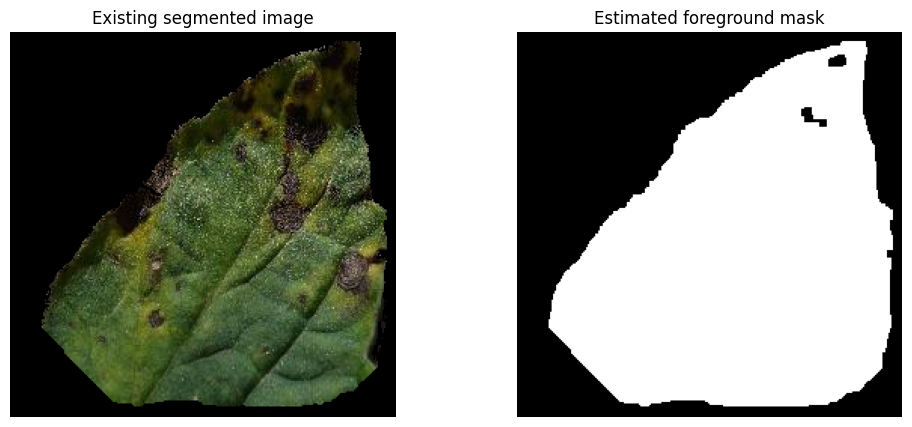

In [ ]:
example_class = "Tomato___Early_blight"

example_files = [
    p for p in (DATA_DIR / example_class).rglob("*")
    if p.suffix.lower() in IMAGE_EXTS
]

if not example_files:
    raise FileNotFoundError(
        f"No images found under {DATA_DIR / example_class}"
    )

example_rgb, example_fg = load_segmented_image(example_files[0])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(example_rgb)
ax[0].set_title("Existing segmented image")
ax[1].imshow(example_fg, cmap="gray")
ax[1].set_title("Estimated foreground mask")
for a in ax:
    a.axis("off")
plt.show()

In [ ]:
def get_feature_image(rgb, feature_name):
    """
    Convert RGB to the selected feature space.
    Return float features per pixel.
    """
    rgb_u8 = rgb.astype(np.uint8)

    if feature_name == "Lab_ab":
        lab = cv2.cvtColor(rgb_u8, cv2.COLOR_RGB2LAB).astype(np.float32)
        # OpenCV Lab a*, b* are offset by 128 in uint8 form.
        features = lab[:, :, 1:3] - 128.0

    elif feature_name == "Lab_Lab":
        lab = cv2.cvtColor(rgb_u8, cv2.COLOR_RGB2LAB).astype(np.float32)
        features = lab.copy()
        features[:, :, 1:3] -= 128.0

    elif feature_name == "HSV_circular":
        hsv = cv2.cvtColor(rgb_u8, cv2.COLOR_RGB2HSV).astype(np.float32)

        # OpenCV hue range is 0–179; convert to radians.
        angle = hsv[:, :, 0] * (2.0 * np.pi / 180.0)
        saturation = hsv[:, :, 1] / 255.0

        features = np.stack([
            np.cos(angle),
            np.sin(angle),
            saturation
        ], axis=-1)

    else:
        raise ValueError(f"Unknown feature space: {feature_name}")

    return features

In [ ]:
def run_kmeans(rgb, fg_mask, feature_name, k, random_state=0):
    feature_img = get_feature_image(rgb, feature_name)

    # Only foreground pixels enter K-means.
    X = feature_img[fg_mask].astype(np.float32)

    if len(X) <= k:
        raise ValueError("Not enough foreground pixels for this K.")

    model = KMeans(
        n_clusters=k,
        random_state=random_state,
        n_init=10,
        max_iter=300
    )

    labels = model.fit_predict(X)

    dbi = (
        davies_bouldin_score(X, labels)
        if len(np.unique(labels)) > 1
        else np.nan
    )

    label_image = np.full(fg_mask.shape, -1, dtype=np.int16)
    label_image[fg_mask] = labels

    # Cluster pixel proportions, calculated over foreground only.
    counts = np.bincount(labels, minlength=k)
    proportions = counts / counts.sum()

    return {
        "labels": labels,
        "label_image": label_image,
        "dbi": float(dbi),
        "centers": model.cluster_centers_,
        "proportions": proportions,
        "feature_image": feature_img
    }

In [ ]:
FEATURES = ["Lab_ab", "Lab_Lab", "HSV_circular"]
K_VALUES = [2, 3, 4]

experiment_results = {}

for feature_name in FEATURES:
    for k in K_VALUES:
        result = run_kmeans(
            example_rgb, example_fg, feature_name, k
        )
        experiment_results[(feature_name, k)] = result

        fig, axes = plt.subplots(1, k + 1, figsize=(3 * (k + 1), 4))
        axes[0].imshow(example_rgb)
        axes[0].set_title("Input")

        for cluster_id in range(k):
            cluster_mask = (
                result["label_image"] == cluster_id
            )

            # Show only pixels in this cluster.
            display = np.zeros_like(example_rgb)
            display[cluster_mask] = example_rgb[cluster_mask]

            axes[cluster_id + 1].imshow(display)
            axes[cluster_id + 1].set_title(
                f"Cluster {cluster_id}\n"
                f"{result['proportions'][cluster_id]:.1%}"
            )

        for ax in axes:
            ax.axis("off")

        fig.suptitle(
            f"{feature_name}, K={k}, DBI={result['dbi']:.3f}"
        )
        plt.tight_layout()
        plt.show()

In [ ]:
DISEASE_CLASSES = [
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus"
]

N_IMAGES_PER_CLASS = 3
all_records = []

for class_name in DISEASE_CLASSES:
    class_dir = DATA_DIR / class_name

    if not class_dir.exists():
        print("Missing class folder:", class_dir)
        continue

    files = sorted([
        p for p in class_dir.rglob("*")
        if p.suffix.lower() in IMAGE_EXTS
    ])[:N_IMAGES_PER_CLASS]

    for image_path in files:
        try:
            rgb, fg = load_segmented_image(image_path)

            for feature_name in FEATURES:
                for k in K_VALUES:
                    result = run_kmeans(rgb, fg, feature_name, k)

                    all_records.append({
                        "class": class_name,
                        "image": image_path.name,
                        "feature": feature_name,
                        "K": k,
                        "DBI": result["dbi"],
                        "foreground_fraction": float(fg.mean()),
                        "cluster_proportions": result["proportions"].tolist()
                    })

        except Exception as e:
            print("Skipped:", image_path, "|", e)

results_df = pd.DataFrame(all_records)
results_csv = OUTPUT_DIR / "experiment1_2_dbi_results.csv"
results_df.to_csv(results_csv, index=False)

display(results_df.head(15))
print("Saved:", results_csv)

TypeError: 'numpy.ndarray' object is not callable

In [ ]:
dbi_summary = (
    results_df
    .groupby(["class", "feature", "K"], as_index=False)
    .agg(
        mean_DBI=("DBI", "mean"),
        std_DBI=("DBI", "std"),
        n_images=("image", "nunique")
    )
    .sort_values(["class", "mean_DBI"])
)

display(dbi_summary)

In [ ]:
REFERENCE_DIR = Path(
    "/content/drive/MyDrive/tomato_lesion_reference_masks"
)
REFERENCE_DIR.mkdir(parents=True, exist_ok=True)

print("Create a binary reference mask for each selected image.")
print("Save each mask as a PNG with white = visible lesion, black = not lesion.")
print("Use the exact original image filename, replacing its extension with .png.")

In [ ]:
def binary_metrics(pred_mask, true_mask, valid_mask=None):
    pred = np.asarray(pred_mask, dtype=bool)
    true = np.asarray(true_mask, dtype=bool)

    if valid_mask is not None:
        valid = np.asarray(valid_mask, dtype=bool)
        pred = pred[valid]
        true = true[valid]

    tp = np.logical_and(pred, true).sum()
    fp = np.logical_and(pred, ~true).sum()
    fn = np.logical_and(~pred, true).sum()

    dice = (2 * tp) / (2 * tp + fp + fn + 1e-9)
    iou = tp / (tp + fp + fn + 1e-9)
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)

    return {
        "Dice": float(dice),
        "IoU": float(iou),
        "Precision": float(precision),
        "Recall": float(recall)
    }


def load_reference_mask(mask_path, expected_shape):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise FileNotFoundError(mask_path)

    if mask.shape != expected_shape:
        raise ValueError(
            f"Reference mask shape {mask.shape} does not match "
            f"image shape {expected_shape}: {mask_path}"
        )

    return mask > 127

In [ ]:
validation_records = []

for class_name in DISEASE_CLASSES:
    class_dir = DATA_DIR / class_name
    if not class_dir.exists():
        continue

    image_files = sorted([
        p for p in class_dir.rglob("*")
        if p.suffix.lower() in IMAGE_EXTS
    ])

    # Replace this with your explicitly selected validation filenames
    # once you have created the reference masks.
    for image_path in image_files:
        mask_path = REFERENCE_DIR / f"{image_path.stem}.png"

        if not mask_path.exists():
            continue

        rgb, fg = load_segmented_image(image_path)
        true_lesion = load_reference_mask(mask_path, fg.shape)

        # Do not score outside the foreground.
        true_lesion &= fg

        for feature_name in FEATURES:
            for k in K_VALUES:
                result = run_kmeans(rgb, fg, feature_name, k)

                for cluster_id in range(k):
                    candidate = (
                        result["label_image"] == cluster_id
                    )

                    metrics = binary_metrics(
                        candidate, true_lesion, valid_mask=fg
                    )

                    validation_records.append({
                        "class": class_name,
                        "image": image_path.name,
                        "feature": feature_name,
                        "K": k,
                        "candidate_cluster": cluster_id,
                        "DBI": result["dbi"],
                        **metrics
                    })

validation_df = pd.DataFrame(validation_records)

if validation_df.empty:
    print(
        "No reference masks matched image filenames. "
        "Create reference masks and ensure the stems match."
    )
else:
    validation_df.to_csv(
        OUTPUT_DIR / "validation_candidate_metrics.csv",
        index=False
    )
    display(validation_df.head(20))

In [ ]:
if not validation_df.empty:
    class_summary = (
        validation_df
        .groupby(["class", "feature", "K"], as_index=False)
        .agg(
            Dice=("Dice", "mean"),
            IoU=("IoU", "mean"),
            Precision=("Precision", "mean"),
            Recall=("Recall", "mean"),
            DBI=("DBI", "mean"),
            n_images=("image", "nunique")
        )
        .sort_values(["class", "Dice"], ascending=[True, False])
    )

    display(class_summary)

In [ ]:
# Use this after you have added a "split" column to your validation
# results, or rerun evaluation separately for validation and test images.

if not validation_df.empty:
    validation_summary = (
        validation_df
        .groupby(["feature", "K"], as_index=False)
        .agg(
            mean_Dice=("Dice", "mean"),
            mean_IoU=("IoU", "mean"),
            mean_Precision=("Precision", "mean"),
            mean_Recall=("Recall", "mean"),
            mean_DBI=("DBI", "mean")
        )
        .sort_values("mean_Dice", ascending=False)
    )

    display(validation_summary)

In [ ]:
def show_mask_comparison(rgb, fg, reference, predicted, title=""):
    fig, ax = plt.subplots(1, 4, figsize=(16, 4))

    ax[0].imshow(rgb)
    ax[0].set_title("Segmented image")

    ax[1].imshow(fg, cmap="gray")
    ax[1].set_title("Foreground")

    ax[2].imshow(reference, cmap="gray")
    ax[2].set_title("Manual lesion reference")

    ax[3].imshow(predicted, cmap="gray")
    ax[3].set_title("Predicted candidate")

    for a in ax:
        a.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [ ]:
# Use an image that has a matching manually labelled mask.
image_path = example_files[0]
mask_path = REFERENCE_DIR / f"{image_path.stem}.png"

if mask_path.exists():
    rgb, fg = load_segmented_image(image_path)
    reference = load_reference_mask(mask_path, fg.shape)

    result = run_kmeans(rgb, fg, "Lab_ab", 2)

    # Demonstration only: cluster 0 is NOT assumed to be the disease.
    candidate = result["label_image"] == 0

    show_mask_comparison(
        rgb, fg, reference & fg, candidate,
        title=f"{image_path.name} — Lab a*,b*, K=2"
    )
else:
    print("Create the matching manual reference mask first:", mask_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Image: 0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.png
Class: Tomato___Early_blight


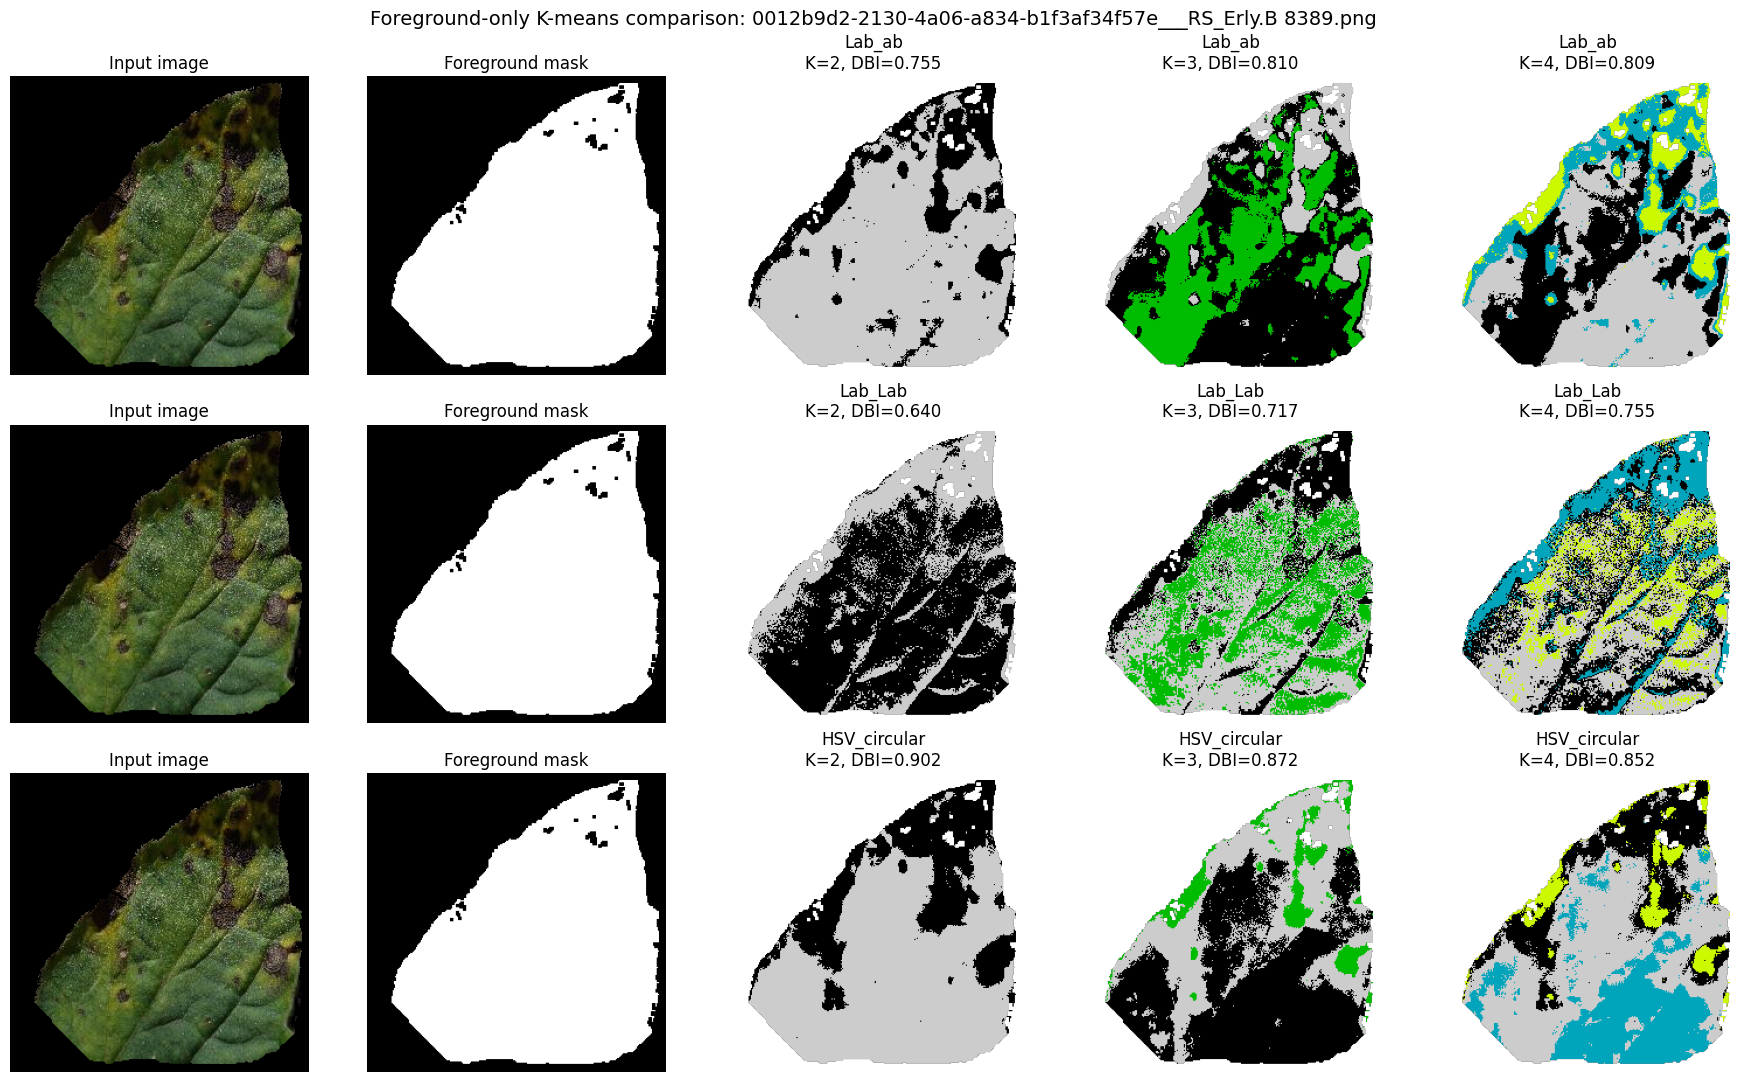


CLUSTER COLOR STATISTICS


TypeError: 'numpy.ndarray' object is not callable

In [ ]:
# ============================================================
# TOMATO LEAF DISEASE SEGMENTATION: ALL EXPERIMENTS IN ONE CELL
# Features: Lab (a*, b*), Lab (L*, a*, b*), circular HSV (H, S)
# K = 2, 3, 4 | Foreground-only clustering | DBI comparison
# ============================================================

!pip -q install opencv-python-headless scikit-learn pandas matplotlib

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score

# ---------------------- CONFIGURATION -----------------------

DATA_DIR = Path(
    "/content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE"
)
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/tomato_kmeans_experiments"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Change this class if you want to test a different disease.
CLASS_NAME = "Tomato___Early_blight"

# Choose an image index from this class: 0, 1, 2, ...
IMAGE_INDEX = 0

FEATURES = ["Lab_ab", "Lab_Lab", "HSV_circular"]
K_VALUES = [2, 3, 4]
RANDOM_STATE = 0

# ---------------------- CHECK DATA --------------------------

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}\n"
        "Check the Google Drive folder path."
    )

CLASS_DIR = DATA_DIR / CLASS_NAME
if not CLASS_DIR.exists():
    raise FileNotFoundError(
        f"Class folder not found: {CLASS_DIR}\n"
        "Check the spelling of CLASS_NAME."
    )

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

image_files = sorted(
    p for p in CLASS_DIR.rglob("*")
    if p.suffix.lower() in IMAGE_EXTS
)

if not image_files:
    raise FileNotFoundError(f"No images found in {CLASS_DIR}")

if IMAGE_INDEX >= len(image_files):
    raise IndexError(
        f"IMAGE_INDEX={IMAGE_INDEX}, but only {len(image_files)} images found."
    )

image_path = image_files[IMAGE_INDEX]
print("Image:", image_path.name)
print("Class:", CLASS_NAME)

# ---------------------- LOAD IMAGE --------------------------

def load_segmented_image(path):
    """
    Read an existing segmented image and estimate its foreground.
    Uses alpha if transparency exists; otherwise estimates foreground
    from border color. This does NOT run GrabCut.
    """
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if img is None:
        raise ValueError(f"Could not read image: {path}")

    if img.ndim == 2:
        rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        alpha = None
    elif img.shape[2] == 4:
        rgb = cv2.cvtColor(img[:, :, :3], cv2.COLOR_BGR2RGB)
        alpha = img[:, :, 3]
    else:
        rgb = cv2.cvtColor(img[:, :, :3], cv2.COLOR_BGR2RGB)
        alpha = None

    if alpha is not None and np.any(alpha < 255):
        fg = alpha > 0
    else:
        h, w = rgb.shape[:2]
        bw = max(2, int(min(h, w) * 0.04))

        border = np.concatenate([
            rgb[:bw].reshape(-1, 3),
            rgb[-bw:].reshape(-1, 3),
            rgb[:, :bw].reshape(-1, 3),
            rgb[:, -bw:].reshape(-1, 3)
        ])

        bg = np.median(border, axis=0)
        dist = np.sqrt(
            np.sum((rgb.astype(np.float32) - bg) ** 2, axis=2)
        )

        # Initial estimate for black or grey background.
        fg = dist > max(12, np.percentile(dist, 90) * 0.10)

        if np.mean(rgb) < 40:
            fg &= np.max(rgb, axis=2) > 15

    # Mild cleanup; inspect the resulting mask visually.
    fg_u8 = (fg.astype(np.uint8) * 255)
    kernel = np.ones((3, 3), np.uint8)
    fg_u8 = cv2.morphologyEx(
        fg_u8, cv2.MORPH_CLOSE, kernel
    )
    fg = fg_u8 > 0

    if fg.mean() < 0.02 or fg.mean() > 0.98:
        print(
            "WARNING: estimated foreground covers "
            f"{fg.mean():.1%} of the image. Inspect the mask."
        )

    return rgb, fg


rgb, foreground = load_segmented_image(image_path)

# ---------------------- COLOR FEATURES ----------------------

def get_features(rgb, feature_name):
    rgb_u8 = rgb.astype(np.uint8)

    if feature_name == "Lab_ab":
        lab = cv2.cvtColor(
            rgb_u8, cv2.COLOR_RGB2LAB
        ).astype(np.float32)
        lab[:, :, 1:3] -= 128.0
        features = lab[:, :, 1:3]

    elif feature_name == "Lab_Lab":
        lab = cv2.cvtColor(
            rgb_u8, cv2.COLOR_RGB2LAB
        ).astype(np.float32)
        lab[:, :, 1:3] -= 128.0
        features = lab

    elif feature_name == "HSV_circular":
        hsv = cv2.cvtColor(
            rgb_u8, cv2.COLOR_RGB2HSV
        ).astype(np.float32)

        # OpenCV hue is 0–179. Encode hue as a circle to avoid
        # treating hues near 0 and 179 as far apart.
        angle = hsv[:, :, 0] * (2.0 * np.pi / 180.0)
        saturation = hsv[:, :, 1] / 255.0

        features = np.stack([
            np.cos(angle),
            np.sin(angle),
            saturation
        ], axis=-1)

    else:
        raise ValueError("Unknown feature name: " + feature_name)

    return features


# ---------------------- K-MEANS -----------------------------

def cluster_foreground(rgb, fg, feature_name, k):
    feature_image = get_features(rgb, feature_name)

    # Only foreground pixels are passed to K-means.
    X = feature_image[fg].astype(np.float32)

    if len(X) <= k:
        raise ValueError("Too few foreground pixels for K-means.")

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10,
        max_iter=300
    )
    labels = model.fit_predict(X)

    dbi = davies_bouldin_score(X, labels)

    label_image = np.full(fg.shape, -1, dtype=np.int16)
    label_image[fg] = labels

    counts = np.bincount(labels, minlength=k)
    proportions = counts / counts.sum()

    # Mean original RGB and Lab colors for interpretation.
    lab = cv2.cvtColor(
        rgb.astype(np.uint8), cv2.COLOR_RGB2LAB
    ).astype(np.float32)
    lab[:, :, 1:3] -= 128.0

    stats = []
    for cluster_id in range(k):
        cmask = label_image == cluster_id
        rgb_pixels = rgb[cmask].astype(np.float32)
        lab_pixels = lab[cmask]

        stats.append({
            "Image": image_path.name,
            "Class": CLASS_NAME,
            "Feature": feature_name,
            "K": k,
            "Cluster": cluster_id,
            "Pixel_percent": round(100 * proportions[cluster_id], 2),
            "Mean_R": round(float(rgb_pixels[:, 0].mean()), 2),
            "Mean_G": round(float(rgb_pixels[:, 1].mean()), 2),
            "Mean_B": round(float(rgb_pixels[:, 2].mean()), 2),
            "Mean_L": round(float(lab_pixels[:, 0].mean()), 2),
            "Mean_a": round(float(lab_pixels[:, 1].mean()), 2),
            "Mean_b": round(float(lab_pixels[:, 2].mean()), 2),
            "DBI": round(float(dbi), 5)
        })

    return label_image, dbi, stats


# ---------------------- RUN ALL COMBINATIONS ---------------

all_stats = []
all_dbi = []
all_labels = {}

for feature_name in FEATURES:
    for k in K_VALUES:
        label_image, dbi, stats = cluster_foreground(
            rgb, foreground, feature_name, k
        )

        all_labels[(feature_name, k)] = label_image
        all_stats.extend(stats)
        all_dbi.append({
            "Image": image_path.name,
            "Class": CLASS_NAME,
            "Feature": feature_name,
            "K": k,
            "DBI": dbi
        })

# ---------------------- DISPLAY MASKS -----------------------

fig, axes = plt.subplots(
    3, 5, figsize=(18, 11),
    gridspec_kw={"width_ratios": [1, 1, 1, 1, 1]}
)

for row, feature_name in enumerate(FEATURES):
    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title("Input image")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(foreground, cmap="gray")
    axes[row, 1].set_title("Foreground mask")
    axes[row, 1].axis("off")

    for col, k in enumerate(K_VALUES, start=2):
        label_image = all_labels[(feature_name, k)]
        dbi = next(
            d["DBI"] for d in all_dbi
            if d["Feature"] == feature_name and d["K"] == k
        )

        # Display only the cluster labels; colors are arbitrary.
        shown = np.ma.masked_where(
            label_image < 0, label_image
        )
        axes[row, col].imshow(
            shown, cmap="nipy_spectral", vmin=0, vmax=k-1
        )
        axes[row, col].set_title(
            f"{feature_name}\nK={k}, DBI={dbi:.3f}"
        )
        axes[row, col].axis("off")

plt.suptitle(
    f"Foreground-only K-means comparison: {image_path.name}",
    fontsize=14
)
plt.tight_layout()
plt.show()

# ---------------------- TABLES AND SAVE ---------------------

cluster_df = pd.DataFrame(all_stats)
dbi_df = pd.DataFrame(all_dbi)

print("\nCLUSTER COLOR STATISTICS")
display(cluster_df)

print("\nDBI COMPARISON")
display(dbi_df.sort_values("DBI"))

cluster_csv = OUTPUT_DIR / f"{image_path.stem}_cluster_statistics.csv"
dbi_csv = OUTPUT_DIR / f"{image_path.stem}_dbi_comparison.csv"

cluster_df.to_csv(cluster_csv, index=False)
dbi_df.to_csv(dbi_csv, index=False)

# Save cluster-label maps for later inspection.
for (feature_name, k), label_image in all_labels.items():
    out = np.zeros(label_image.shape, dtype=np.uint8)
    valid = label_image >= 0
    out[valid] = (
        label_image[valid] * (255 // max(1, k - 1))
    ).astype(np.uint8)

    out_path = OUTPUT_DIR / (
        f"{image_path.stem}_{feature_name}_K{k}_labels.png"
    )
    cv2.imwrite(str(out_path), out)

print("\nSaved results to:", OUTPUT_DIR)
print("Cluster statistics:", cluster_csv)
print("DBI comparison:", dbi_csv)

print(
    "\nINTERPRETATION:\n"
    "- Lower DBI means more compact/separated clusters, not necessarily better lesion masks.\n"
    "- Cluster-label map colors are arbitrary; inspect the spatial regions.\n"
    "- Check whether the foreground mask excludes the background correctly.\n"
    "- To prove which cluster contains lesions, compare candidates with manually labelled lesion masks."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Disease classes found: 9
['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus']


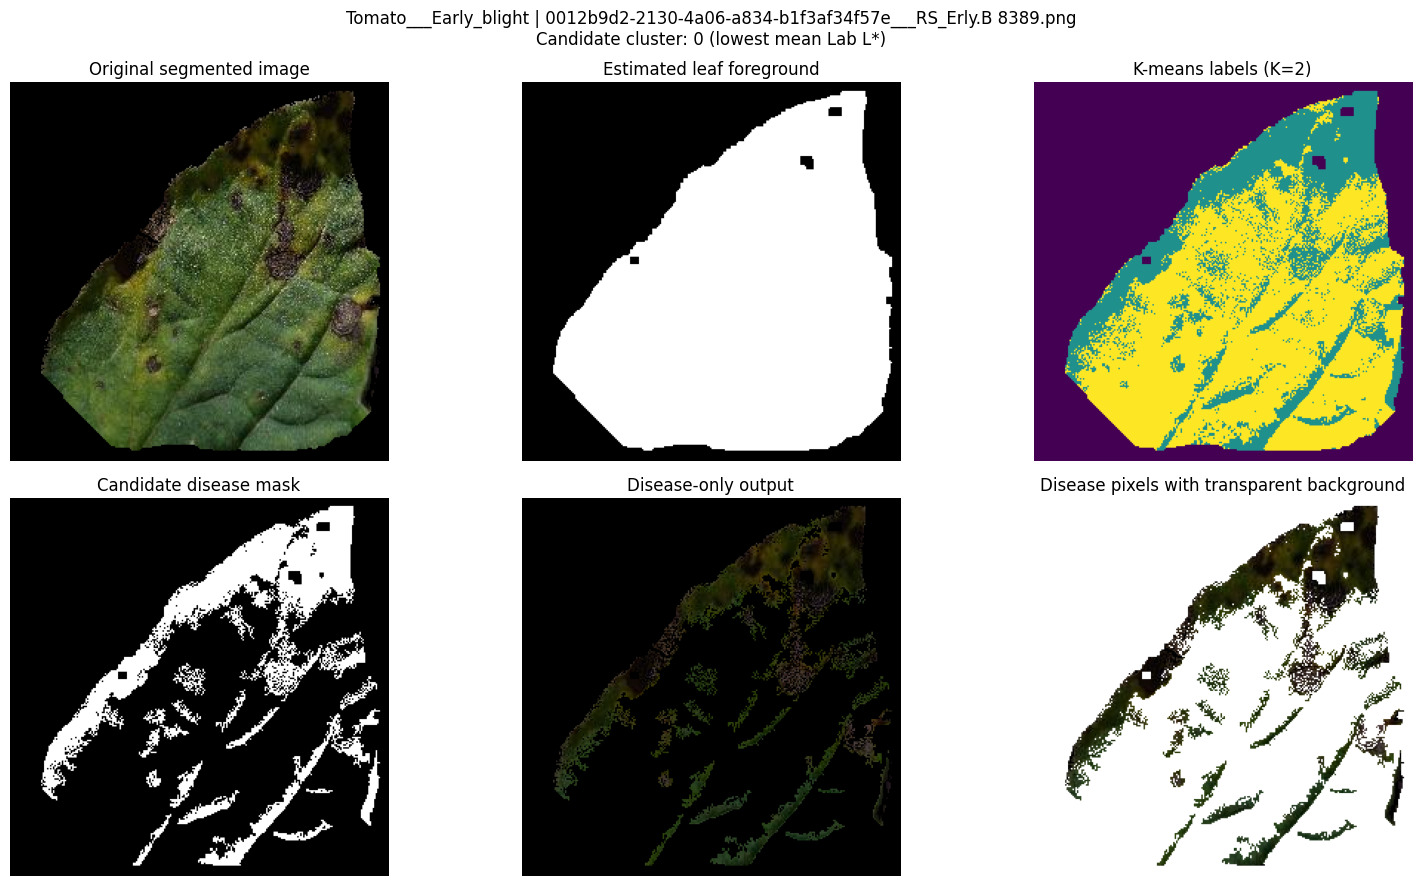

Image: 0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.png
Selected candidate cluster: 0
Foreground pixels: 38352
Candidate lesion pixels after cleanup: 11554
Candidate lesion fraction of foreground: 30.13%


,Cluster,Mean_Lab_Lightness
0,0,40.627743
1,1,102.567192



Saved outputs to: /content/drive/MyDrive/tomato_disease_only_outputs/Tomato___Early_blight
Files:
0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389_disease_mask.png
0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389_disease_only.png
0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389_disease_transparent.png


In [ ]:

# ============================================================
# TOMATO DISEASE-ONLY SEGMENTATION USING COLOR-ONLY K-MEANS
# Reuses existing segmented images; does NOT rerun GrabCut.
# ============================================================

!pip -q install opencv-python-headless scikit-learn

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.cluster import KMeans
from IPython.display import display as show_table
import pandas as pd

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Dataset settings
DATASET_DIR = (
    '/content/drive/MyDrive/'
    'tomato_grey_refined_segmented_COMPLETE'
)

OUTPUT_DIR = (
    '/content/drive/MyDrive/'
    'tomato_disease_only_outputs'
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Choose a diseased class folder
CLASS_NAME = 'Tomato___Early_blight'

# Number of image to process from this folder
IMAGE_INDEX = 0

# K-means configuration
K = 2
RANDOM_STATE = 42

# Process only disease folders, excluding healthy
disease_classes = [
    name for name in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, name))
    and 'healthy' not in name.lower()
]

print("Disease classes found:", len(disease_classes))
print(disease_classes)

# 3. Find an image in the selected class
class_dir = os.path.join(DATASET_DIR, CLASS_NAME)

if not os.path.isdir(class_dir):
    raise FileNotFoundError(
        f"Class folder not found: {class_dir}\n"
        f"Available classes: {disease_classes}"
    )

image_files = sorted([
    f for f in os.listdir(class_dir)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
])

if not image_files:
    raise ValueError(f"No images found in {class_dir}")

if IMAGE_INDEX >= len(image_files):
    raise IndexError(
        f"IMAGE_INDEX={IMAGE_INDEX}, but only "
        f"{len(image_files)} images are available."
    )

image_name = image_files[IMAGE_INDEX]
image_path = os.path.join(class_dir, image_name)

# Read image while preserving alpha if present
image = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)
if image is None:
    raise ValueError(f"Could not read image: {image_path}")

if image.ndim == 3 and image.shape[2] == 4:
    bgr = image[:, :, :3]
    alpha = image[:, :, 3]
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    foreground = alpha > 0
else:
    if image.ndim == 2:
        rgb = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    else:
        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Fallback foreground estimate:
    # assumes background is relatively uniform near image borders.
    # Use your actual saved GrabCut mask instead if available.
    h, w = rgb.shape[:2]
    border = np.concatenate([
        rgb[0, :, :],
        rgb[-1, :, :],
        rgb[:, 0, :],
        rgb[:, -1, :]
    ], axis=0).astype(np.float32)

    bg_color = np.median(border, axis=0)
    distance = np.linalg.norm(
        rgb.astype(np.float32) - bg_color, axis=2
    )

    foreground = distance > 20

    # Smooth small gaps in the estimated foreground
    foreground_u8 = (foreground.astype(np.uint8) * 255)
    kernel = np.ones((5, 5), np.uint8)
    foreground_u8 = cv2.morphologyEx(
        foreground_u8, cv2.MORPH_CLOSE, kernel
    )
    foreground = foreground_u8 > 0

# 4. Convert image to CIELAB color space
lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)

# Use all three Lab channels: L*, a*, b*
features_image = lab.copy()
features_image[:, :, 1:] -= 128.0

# Use only pixels classified as foreground
valid_pixels = np.flatnonzero(foreground.ravel())

if len(valid_pixels) < K:
    raise ValueError(
        "Too few foreground pixels. Check the foreground mask."
    )

X = features_image.reshape(-1, 3)[valid_pixels]

# 5. Run K-means
model = KMeans(
    n_clusters=K,
    random_state=RANDOM_STATE,
    n_init=10
)
labels = model.fit_predict(X)

label_image = np.full(foreground.size, -1, dtype=np.int16)
label_image[valid_pixels] = labels
label_image = label_image.reshape(foreground.shape)

# 6. Select the cluster with the lowest mean Lab lightness.
# This is only a heuristic for candidate lesion pixels.
mean_lightness = {}

for cluster_id in range(K):
    pixels = X[labels == cluster_id]
    mean_lightness[cluster_id] = float(pixels[:, 0].mean())

candidate_cluster = min(
    mean_lightness, key=mean_lightness.get
)

disease_mask = (
    (label_image == candidate_cluster) & foreground
)

# Remove tiny isolated specks (adjust threshold if needed)
mask_u8 = disease_mask.astype(np.uint8) * 255
num_labels, components, stats, _ = (
    cv2.connectedComponentsWithStats(mask_u8, 8)
)

MIN_AREA = 20
clean_mask = np.zeros_like(mask_u8)

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]
    if area >= MIN_AREA:
        clean_mask[components == i] = 255

# 7. Produce disease-only image on a black background
disease_only = np.zeros_like(rgb)
disease_only[clean_mask > 0] = rgb[clean_mask > 0]

# Optional transparent-background output
rgba_output = np.dstack([rgb, clean_mask])

# 8. Save results
safe_class = CLASS_NAME.replace('/', '_')
stem = os.path.splitext(image_name)[0]
save_dir = os.path.join(OUTPUT_DIR, safe_class)
os.makedirs(save_dir, exist_ok=True)

cv2.imwrite(
    os.path.join(save_dir, stem + '_disease_mask.png'),
    clean_mask
)
cv2.imwrite(
    os.path.join(save_dir, stem + '_disease_only.png'),
    cv2.cvtColor(disease_only, cv2.COLOR_RGB2BGR)
)
cv2.imwrite(
    os.path.join(save_dir, stem + '_disease_transparent.png'),
    cv2.cvtColor(rgba_output, cv2.COLOR_RGBA2BGRA)
)

# 9. Display final results
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes[0, 0].imshow(rgb)
axes[0, 0].set_title('Original segmented image')

axes[0, 1].imshow(foreground, cmap='gray')
axes[0, 1].set_title('Estimated leaf foreground')

axes[0, 2].imshow(label_image, cmap='viridis')
axes[0, 2].set_title(f'K-means labels (K={K})')

axes[1, 0].imshow(clean_mask, cmap='gray', vmin=0, vmax=255)
axes[1, 0].set_title('Candidate disease mask')

axes[1, 1].imshow(disease_only)
axes[1, 1].set_title('Disease-only output')

axes[1, 2].imshow(rgba_output)
axes[1, 2].set_title('Disease pixels with transparent background')

for ax in axes.flat:
    ax.axis('off')

plt.suptitle(
    f'{CLASS_NAME} | {image_name}\n'
    f'Candidate cluster: {candidate_cluster} '
    f'(lowest mean Lab L*)',
    fontsize=12
)
plt.tight_layout()
plt.show()

# 10. Print summary
summary = pd.DataFrame({
    'Cluster': list(mean_lightness.keys()),
    'Mean_Lab_Lightness': list(mean_lightness.values())
})

print("Image:", image_name)
print("Selected candidate cluster:", candidate_cluster)
print("Foreground pixels:", int(foreground.sum()))
print("Candidate lesion pixels after cleanup:", int(
    np.count_nonzero(clean_mask)
))
print("Candidate lesion fraction of foreground: {:.2f}%".format(
    100 * np.count_nonzero(clean_mask) /
    max(1, foreground.sum())
))
show_table(summary)

print("\nSaved outputs to:", save_dir)
print("Files:")
print(stem + '_disease_mask.png')
print(stem + '_disease_only.png')
print(stem + '_disease_transparent.png')
